In [29]:
# Phishing Website Detection Using Supervised Machine Learning

## 1. Introduction
## 2. Dataset Collection and Understanding
## 3. Data Preprocessing
## 4. Exploratory Data Analysis
## 5. Train-Test Split
## 6. Baseline Classification Models
## 7. Advanced Classification Models
## 8. Hyperparameter Optimization
## 9. Model Evaluation
## 10. Feature Importance
## 11. Final Model Selection
## 12. Conclusion and Future Scope

In [30]:
# Import required libraries

import pandas as pd
import numpy as np

# Upload the dataset

from google.colab import files

uploaded = files.upload()

Saving dataset_B_05_2020.csv to dataset_B_05_2020 (1).csv


In [31]:
# Load the uploaded dataset

import io

file_name = next(iter(uploaded))

if not file_name.lower().endswith(".csv"):
    raise ValueError("Please upload the extracted CSV file.")

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display dataset information

print("Dataset Loaded Successfully!")

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.drop(columns=["url"]).head())

print("\nDataset Information:")
df.info()

Dataset Loaded Successfully!

Dataset Shape: (11430, 89)

Column Names:
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyper

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percen

In [32]:
## 3. Data Quality Analysis

### 3.1 Missing Value Analysis
### 3.2 Duplicate Record Analysis
### 3.3 Target Class Distribution

In [33]:
# 1. Missing Value Analysis

print("MISSING VALUE ANALYSIS")

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns containing missing values:")
print(missing_values[missing_values > 0])


# 2. Duplicate Record Analysis

print("\nDUPLICATE ANALYSIS")

duplicate_rows = df.duplicated().sum()

duplicate_urls = df["url"].duplicated().sum()

print("Total duplicate rows:", duplicate_rows)
print("Total duplicate URLs:", duplicate_urls)


# 3. Target Variable Analysis

print("\nTARGET VARIABLE ANALYSIS")

print("Unique target labels:")
print(df["status"].unique())

class_counts = df["status"].value_counts()

print("\nClass Counts:")
print(class_counts)

print("\nClass Percentages:")
print(df["status"].value_counts(normalize=True) * 100)

MISSING VALUE ANALYSIS
Total missing values: 0

Columns containing missing values:
Series([], dtype: int64)

DUPLICATE ANALYSIS
Total duplicate rows: 0
Total duplicate URLs: 1

TARGET VARIABLE ANALYSIS
Unique target labels:
['legitimate' 'phishing']

Class Counts:
status
legitimate    5715
phishing      5715
Name: count, dtype: int64

Class Percentages:
status
legitimate    50.0
phishing      50.0
Name: proportion, dtype: float64


### Data Quality Analysis – Observations

The dataset was analysed for missing values, duplicate records, duplicate URLs, and target class distribution.

The analysis revealed that the dataset contains no missing values and no exact duplicate records.

One duplicate URL occurrence was identified and will be inspected before making any removal decision.

The target variable contains 5,715 legitimate website records and 5,715 phishing website records, representing 50% of each class.

Therefore, the dataset is balanced, and additional class balancing techniques such as SMOTE are not initially required.

In [34]:


# Identify repeated URLs

duplicate_url_rows = df[
    df.duplicated(subset="url", keep=False)
].sort_values("url")

print("Records containing repeated URLs:")

display(duplicate_url_rows[["status"]])

# Check whether repeated URLs have different feature values

feature_columns = [
    col for col in df.columns
    if col not in ["url", "status"]
]

for url, group in duplicate_url_rows.groupby("url"):

    print("\nURL:", url)

    print("Number of records:", len(group))

    print("Target labels:", group["status"].tolist())

    different_features = (
        group[feature_columns]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

    print("Number of differing features:", different_features)

Records containing repeated URLs:


,url,status
6035,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,phishing



URL: http://e710z0ear.du.r.appspot.com/c:/users/user/downlo
Number of records: 2
Target labels: ['phishing', 'phishing']
Number of differing features: 10


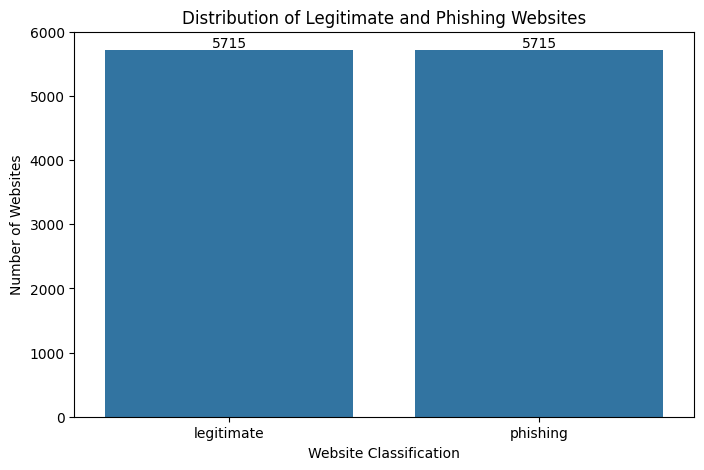

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="status",
    order=["legitimate", "phishing"]
)

ax.bar_label(ax.containers[0])

plt.title("Distribution of Legitimate and Phishing Websites")

plt.xlabel("Website Classification")

plt.ylabel("Number of Websites")

plt.show()

### Target Distribution and Duplicate URL Analysis

The target variable contains 5,715 legitimate websites and
5,715 phishing websites, representing an equal distribution
of both classes.

The dataset is therefore balanced, and additional class
balancing techniques are not initially required.

During duplicate URL analysis, one URL was identified
appearing in two records. However, these records contain
10 differing extracted feature values and have the same
phishing classification.

Since the records are not exact duplicates, both will
be retained for further analysis. During model evaluation,
group-aware splitting will be used to prevent the same
URL from appearing in both training and testing datasets.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Feature Distribution Analysis

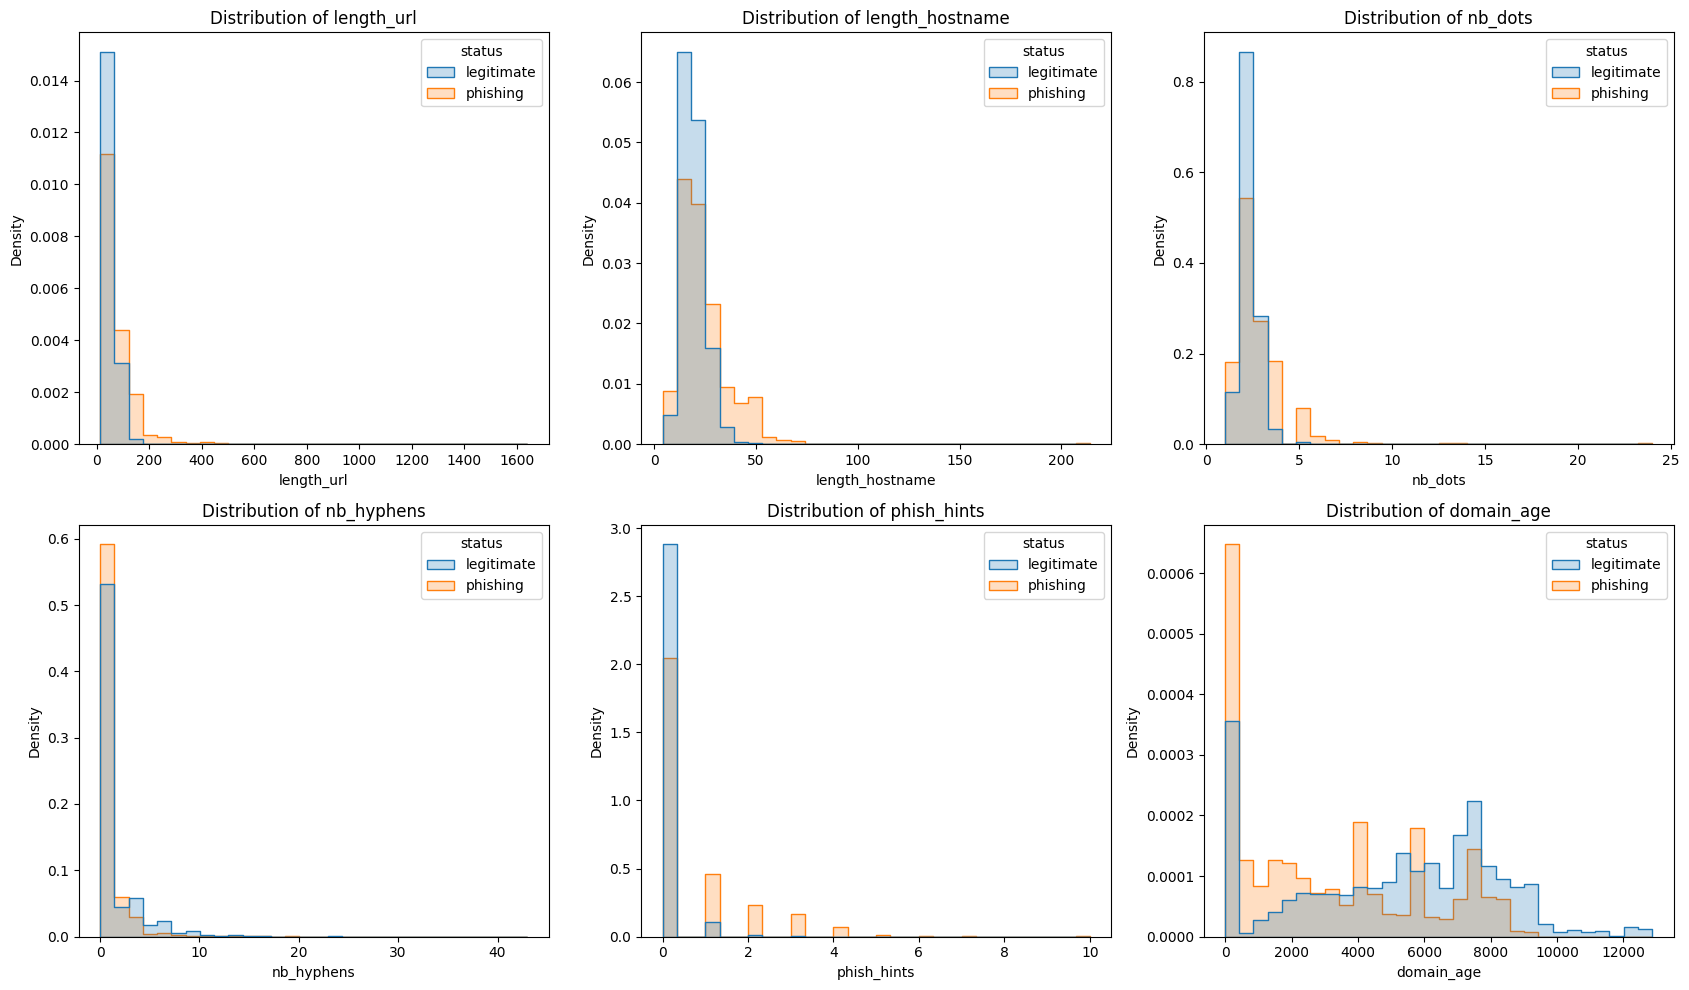

In [36]:
# Select important website features

selected_features = [
    "length_url",
    "length_hostname",
    "nb_dots",
    "nb_hyphens",
    "phish_hints",
    "domain_age"
]

# Create distribution plots

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    sns.histplot(
        data=df,
        x=feature,
        hue="status",
        bins=30,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")

    axes[i].set_xlabel(feature)

    axes[i].set_ylabel("Density")

plt.tight_layout()

plt.show()

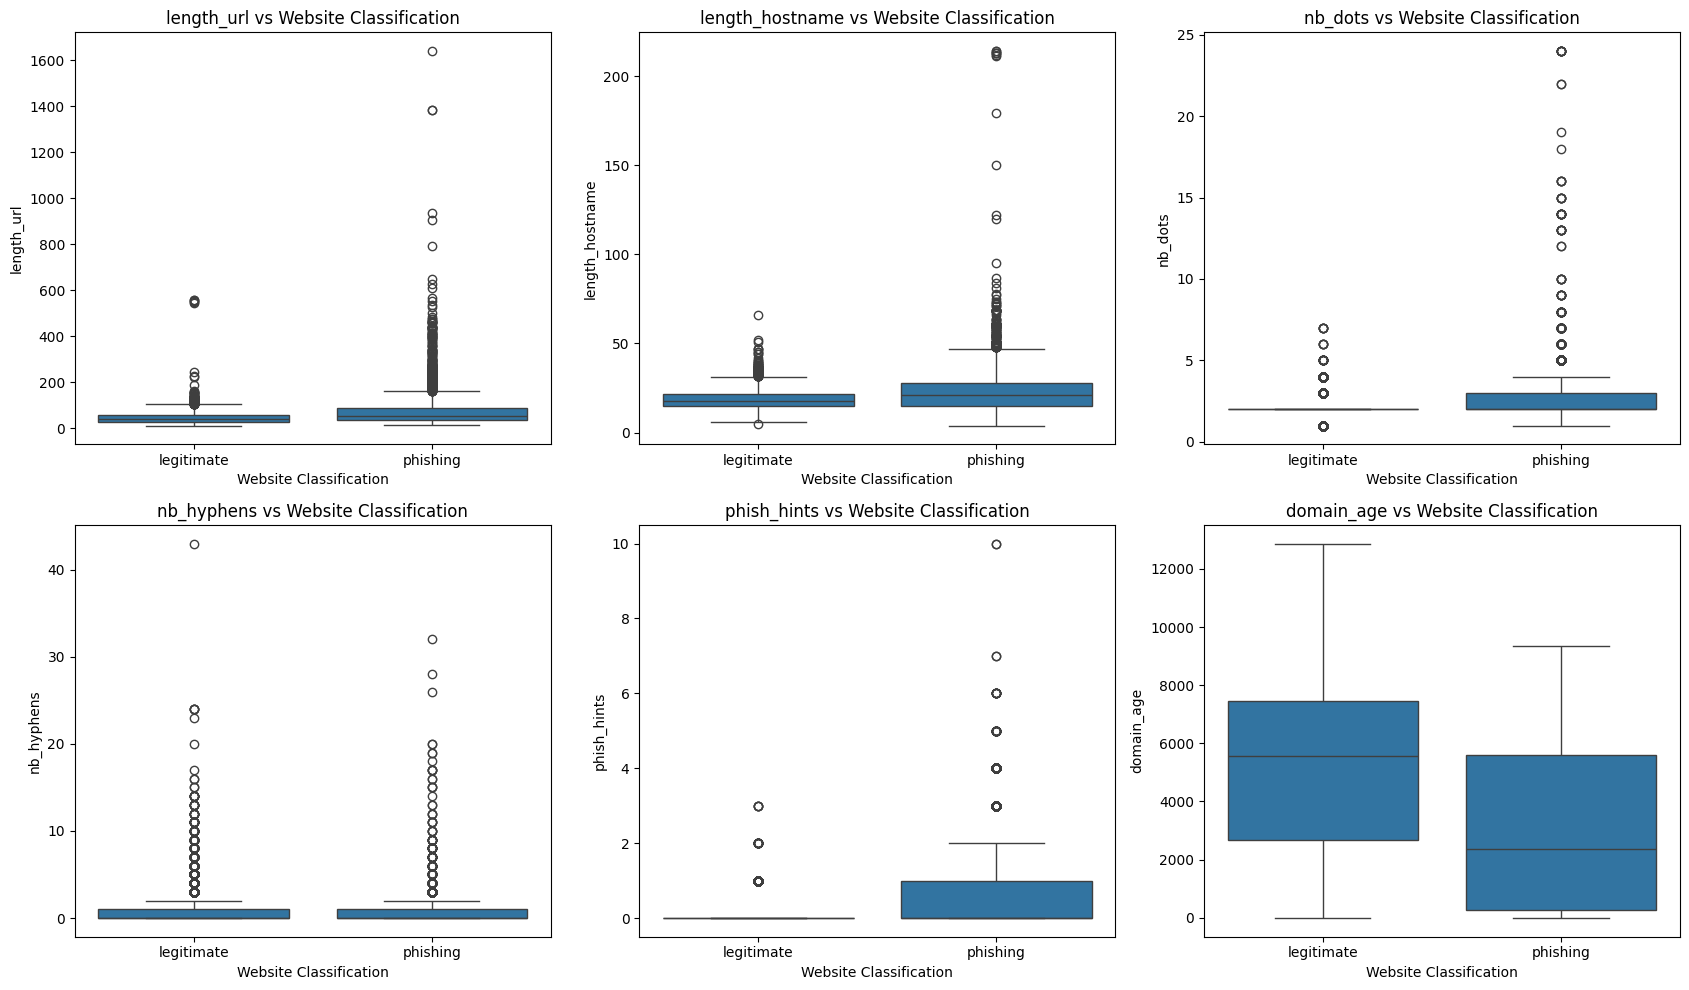

In [37]:
# Compare feature distributions between website classes

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    sns.boxplot(
        data=df,
        x="status",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Website Classification")

    axes[i].set_xlabel("Website Classification")

    axes[i].set_ylabel(feature)

plt.tight_layout()

plt.show()

In [38]:
# Descriptive statistics of selected features

print("DESCRIPTIVE STATISTICS")

display(df[selected_features].describe().T)

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
length_url,11430.0,61.126684,55.297318,12.0,33.00,47.0,71.00,1641.0
length_hostname,11430.0,21.090289,10.777171,4.0,15.00,19.0,24.00,214.0
nb_dots,11430.0,2.480752,1.369686,1.0,2.00,2.0,3.00,24.0
nb_hyphens,11430.0,0.997550,2.087087,0.0,0.00,0.0,1.00,43.0
phish_hints,11430.0,0.327734,0.842600,0.0,0.00,0.0,0.00,10.0
domain_age,11430.0,4062.543745,3107.784600,-12.0,972.25,3993.0,7026.75,12874.0


### 4.1 Feature Distribution Analysis – Observations

The distribution analysis was performed on six selected website
features: length_url, length_hostname, nb_dots, nb_hyphens,
phish_hints, and domain_age.

The analysis indicates that phishing URLs generally exhibit
greater variation in URL length and hostname length.

The number of dots and phishing-related hints also show
differences between the two website classes.

The domain_age feature indicates differences in domain age
distributions between legitimate and phishing websites.

The boxplots reveal several extreme observations across
the selected numerical features.

These observations suggest that website characteristics
may provide useful information for phishing classification.
However, further statistical analysis and model evaluation
are required to determine their actual predictive importance.

In [39]:
# Investigate negative domain age values

negative_age = df[df["domain_age"] < 0]

print("Number of negative domain_age values:",
      len(negative_age))

print("\nNegative domain_age distribution:")

print(negative_age["domain_age"].value_counts().sort_index())

print("\nClass distribution of negative domain ages:")

print(negative_age["status"].value_counts())

print("\nRecords with negative domain age:")

display(
    negative_age[["url", "domain_age", "status"]].head(10)
)

Number of negative domain_age values: 1837

Negative domain_age distribution:
domain_age
-12       1
-2       55
-1     1781
Name: count, dtype: int64

Class distribution of negative domain ages:
status
phishing      994
legitimate    843
Name: count, dtype: int64

Records with negative domain age:


,url,domain_age,status
0,http://www.crestonwood.com/router.php,-1,legitimate
3,http://rgipt.ac.in,-1,legitimate
5,http://appleid.apple.com-app.es/,-1,phishing
10,https://www.astrologyonline.eu/Astro_MemoNew/P...,-1,legitimate
29,http://www.inbioma.pe/rechnung-376440790464490...,-1,phishing
38,http://www.j-net.cn/cms,-1,legitimate
48,https://www.bls.gov/oes/current/oes292035.htm,-1,legitimate
70,http://baghira-wupperwolf.de/images/banners/bb...,-1,phishing
83,http://www.calculate.co.il/,-1,legitimate
84,http://marketinghelper.com.au/themes/sports/wp...,-1,phishing


In [40]:
# Outlier detection using IQR

outlier_results = []

for feature in selected_features:

    Q1 = df[feature].quantile(0.25)

    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_results.append({
        "Feature": feature,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,length_url,-24.0,128.0,620,5.42
1,length_hostname,1.5,37.5,775,6.78
2,nb_dots,0.5,4.5,567,4.96
3,nb_hyphens,-1.5,2.5,1371,11.99
4,phish_hints,0.0,0.0,2041,17.86
5,domain_age,-8109.5,16108.5,0,0.00


In [41]:
# Convert target labels into numerical values for correlation analysis

target_numeric = df["status"].map({
    "legitimate": 0,
    "phishing": 1
})

# Select all numerical features

numeric_features = df.select_dtypes(
    include=np.number
).columns.tolist()

# Calculate correlation with target

target_correlation = (
    df[numeric_features]
    .corrwith(target_numeric)
    .dropna()
)

# Sort by absolute correlation

target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(
        ascending=False
    ).index
)

print("Top 15 features correlated with phishing classification:")

display(
    target_correlation.head(15).to_frame(
        name="Correlation with Phishing"
    )
)

Top 15 features correlated with phishing classification:


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Correlation with Phishing
google_index,0.731171
page_rank,-0.511137
nb_www,-0.443468
ratio_digits_url,0.356395
domain_in_title,0.342807
nb_hyperlinks,-0.342628
phish_hints,0.335393
domain_age,-0.331889
ip,0.321698
nb_qm,0.294319


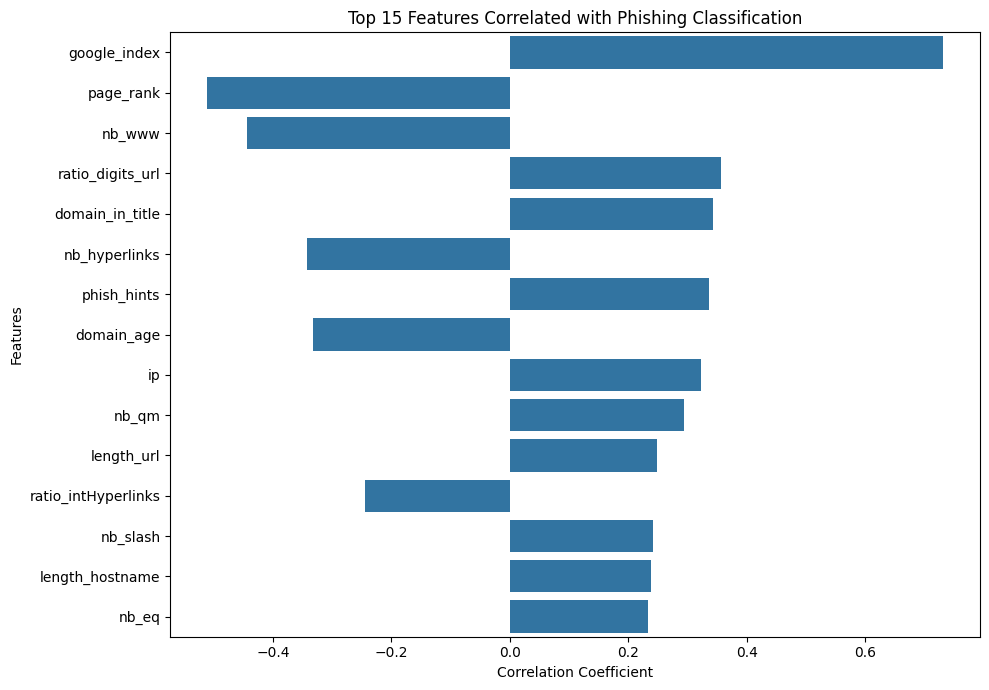

In [42]:
# Select the top 15 correlated features

top_features = target_correlation.head(15).index.tolist()

plt.figure(figsize=(10, 7))

sns.barplot(
    x=target_correlation.head(15).values,
    y=target_correlation.head(15).index
)

plt.title("Top 15 Features Correlated with Phishing Classification")

plt.xlabel("Correlation Coefficient")

plt.ylabel("Features")

plt.tight_layout()

plt.show()

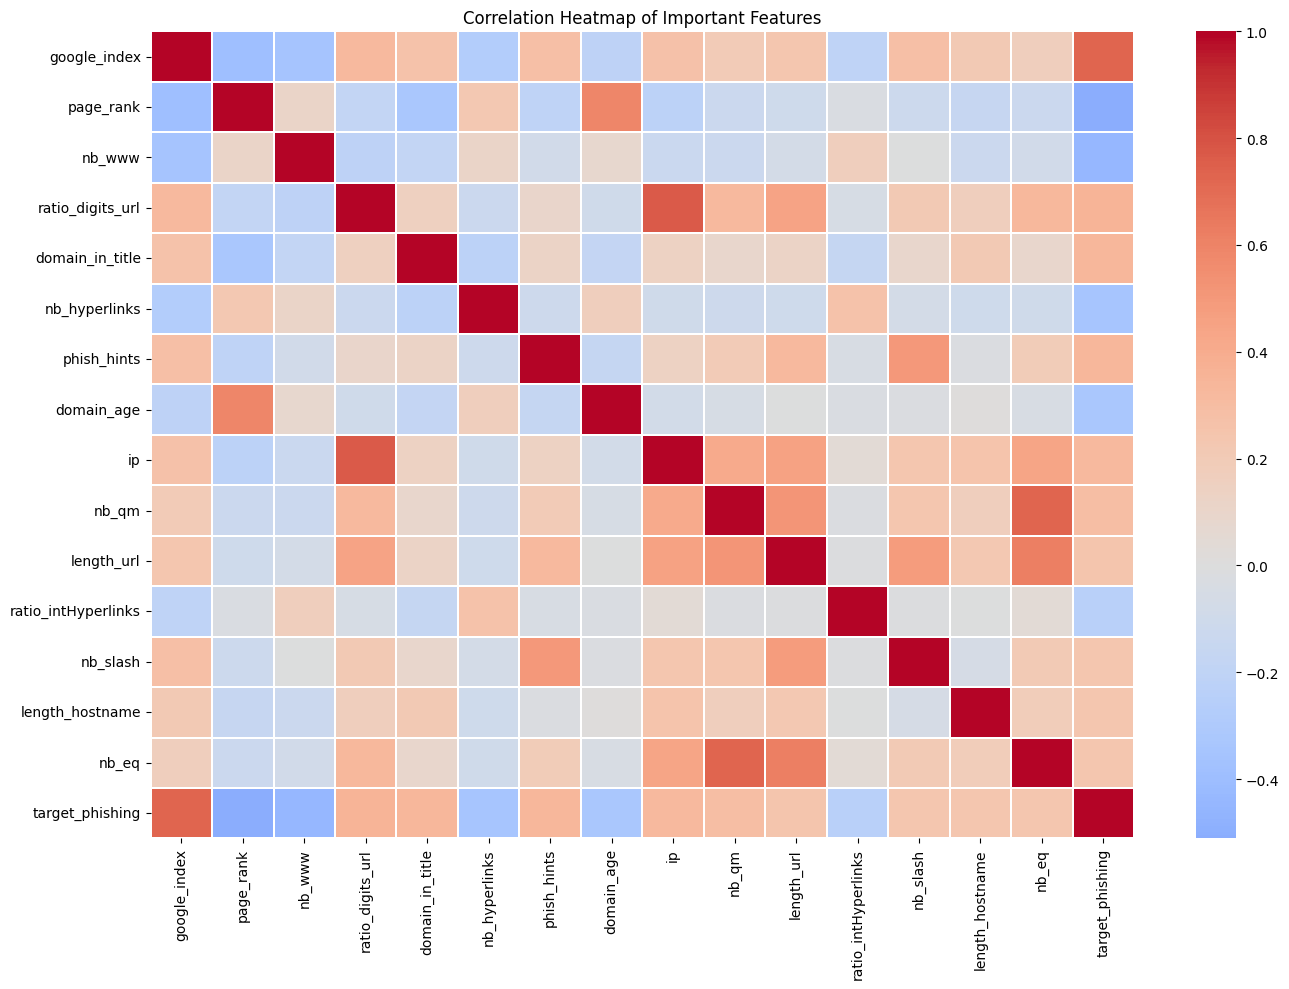

In [43]:
# Prepare data for correlation heatmap

correlation_data = df[top_features].copy()

correlation_data["target_phishing"] = target_numeric

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Important Features")

plt.tight_layout()

plt.show()

### 4.2 Correlation Analysis – Observations

Correlation analysis was performed to identify relationships
between website features and the phishing classification target.

The strongest positive correlation was observed for google_index
with a correlation coefficient of approximately 0.731.

Other features showing notable associations included page_rank,
nb_www, ratio_digits_url, domain_in_title, and phish_hints.

The correlation heatmap also helped identify relationships
between individual numerical features.

These observations suggest that URL characteristics,
webpage properties, and external website information can
contribute to phishing website classification.

However, correlation alone cannot determine the actual
predictive performance of a feature. Further model-based
evaluation will be performed.

In [44]:
# 1. Identify constant numerical features

numeric_df = df.select_dtypes(include=np.number)

constant_features = [
    col for col in numeric_df.columns
    if numeric_df[col].nunique(dropna=False) <= 1
]

print("CONSTANT FEATURES")

print("Number of constant features:", len(constant_features))

print(constant_features)


# 2. Identify undefined target correlations

correlation_check = numeric_df.corrwith(target_numeric)

undefined_correlations = correlation_check[
    correlation_check.isna()
]

print("\nFeatures with undefined correlations:")

print(undefined_correlations.index.tolist())


# 3. Inspect phish_hints distribution

print("\nPHISH HINTS DISTRIBUTION")

print(df["phish_hints"].value_counts().sort_index())


# 4. Compare phish_hints across classes

print("\nPHISH HINTS BY WEBSITE CLASS")

display(
    pd.crosstab(
        df["phish_hints"],
        df["status"],
        margins=True
    )
)

CONSTANT FEATURES
Number of constant features: 6
['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']

Features with undefined correlations:
['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']

PHISH HINTS DISTRIBUTION
phish_hints
0     9389
1     1079
2      460
3      325
4      136
5       28
6        9
7        2
10       2
Name: count, dtype: int64

PHISH HINTS BY WEBSITE CLASS


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


status,legitimate,phishing,All
phish_hints,,,
0,5489,3900,9389
1,198,881,1079
2,24,436,460
3,4,321,325
4,0,136,136
5,0,28,28
6,0,9,9
7,0,2,2
10,0,2,2


### 4.3 Constant Feature and Phishing Hints Analysis

Six numerical features were identified as constant features:
nb_or, ratio_nullHyperlinks, ratio_intRedirection,
ratio_intErrors, submit_email, and sfh.

These features were excluded from the predictive feature set
because they do not provide variation for classification.

The phish_hints feature was also investigated. Records with
higher phishing-hint values were predominantly associated
with the phishing class.

Among 2,041 records with nonzero phishing hints, 1,815
belonged to the phishing class.

Therefore, phish_hints was retained as a potentially
important predictive feature.

The EDA stage identified useful patterns, possible outliers,
and features requiring further preprocessing.

## 5. Data Preprocessing

### 5.1 Feature Selection and Unnecessary Column Removal

In [45]:
# Create a copy of the original dataset

df_processed = df.copy()

# Identify constant features

constant_features = [
    "nb_or",
    "ratio_nullHyperlinks",
    "ratio_intRedirection",
    "ratio_intErrors",
    "submit_email",
    "sfh"
]

# Separate independent features and target

X = df_processed.drop(
    columns=["url", "status"] + constant_features
).copy()

y = df_processed["status"].map({
    "legitimate": 0,
    "phishing": 1
})

print("Original Dataset Shape:", df.shape)

print("Features after removing unnecessary columns:", X.shape)

print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.value_counts())

Original Dataset Shape: (11430, 89)
Features after removing unnecessary columns: (11430, 81)
Target Shape: (11430,)

Target Classes:
status
0    5715
1    5715
Name: count, dtype: int64


In [46]:
# Create an indicator for unavailable domain age

X["domain_age_unavailable"] = (
    X["domain_age"] < 0
).astype(int)

# Replace negative domain ages with NaN

X.loc[X["domain_age"] < 0, "domain_age"] = np.nan

print("Domain Age Preprocessing")

print(
    "Unavailable domain age records:",
    X["domain_age"].isna().sum()
)

print(
    "Indicator feature count:",
    X["domain_age_unavailable"].sum()
)

print("\nUpdated feature shape:", X.shape)

Domain Age Preprocessing
Unavailable domain age records: 1837
Indicator feature count: 1837

Updated feature shape: (11430, 82)


### 5.2 Train-Test Splitting

The dataset is divided into 70% training data and 30%
testing data using stratified group splitting.

Repeated URLs are kept within the same partition to
prevent URL-level data leakage.

In [47]:
from sklearn.model_selection import StratifiedGroupKFold

# Group records using their original URLs

groups = df_processed["url"]

# Create 10 stratified group folds

sgkf = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Generate all folds

folds = list(sgkf.split(X, y, groups))

# Combine 3 folds to create approximately 30% testing data

test_indices = np.concatenate([
    folds[0][1],
    folds[1][1],
    folds[2][1]
])

# Remaining 7 folds become training data

train_indices = np.setdiff1d(
    np.arange(len(df_processed)),
    test_indices
)

# Split features and target

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

# Display split dimensions

print("TRAINING AND TESTING DATA")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

# Check for URL leakage

train_urls = set(groups.iloc[train_indices])
test_urls = set(groups.iloc[test_indices])

print("\nURL Leakage Check:")

print("Overlapping URLs:", len(train_urls & test_urls))

TRAINING AND TESTING DATA
Training Features: (8002, 82)
Testing Features: (3428, 82)
Training Target: (8002,)
Testing Target: (3428,)

Training Percentage: 70.01 %
Testing Percentage: 29.99 %

URL Leakage Check:
Overlapping URLs: 0


In [48]:
# Compare class distribution in training and testing data

split_distribution = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Testing": y_test.value_counts().reindex([0, 1], fill_value=0)
})

split_distribution.index = [
    "Legitimate (0)",
    "Phishing (1)"
]

print("Class Distribution Across Training and Testing Data")

display(split_distribution)

print("\nTraining Class Percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Percentages:")
print(y_test.value_counts(normalize=True) * 100)

Class Distribution Across Training and Testing Data


,Training,Testing
Legitimate (0),3988,1727
Phishing (1),4014,1701



Training Class Percentages:
status
1    50.162459
0    49.837541
Name: proportion, dtype: float64

Testing Class Percentages:
status
0    50.37923
1    49.62077
Name: proportion, dtype: float64


## 6. Baseline Classification Models

### 6.1 Logistic Regression

In [49]:
# Import Logistic Regression and preprocessing tools

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [50]:
# Create Logistic Regression pipeline

log_reg_model = Pipeline([

    # Handle missing values using training data median

    ("imputer", SimpleImputer(strategy="median")),

    # Scale numerical features

    ("scaler", StandardScaler()),

    # Logistic Regression classifier

    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))

])

# Train the model

log_reg_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [51]:
# Predict the testing data

y_pred_log = log_reg_model.predict(X_test)

print("Predictions Generated Successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred_log[:10])

Predictions Generated Successfully!

First 10 Actual Labels:
[0 1 1 0 1 0 1 0 1 0]

First 10 Predicted Labels:
[0 1 1 0 1 0 1 0 1 0]


In [52]:
# Calculate evaluation metrics

log_accuracy = accuracy_score(y_test, y_pred_log)

log_precision = precision_score(
    y_test, y_pred_log, pos_label=1
)

log_recall = recall_score(
    y_test, y_pred_log, pos_label=1
)

log_f1 = f1_score(
    y_test, y_pred_log, pos_label=1
)

print("LOGISTIC REGRESSION PERFORMANCE")

print("Accuracy :", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall   :", round(log_recall, 4))
print("F1 Score :", round(log_f1, 4))

LOGISTIC REGRESSION PERFORMANCE
Accuracy : 0.951
Precision: 0.9554
Recall   : 0.9453
F1 Score : 0.9504


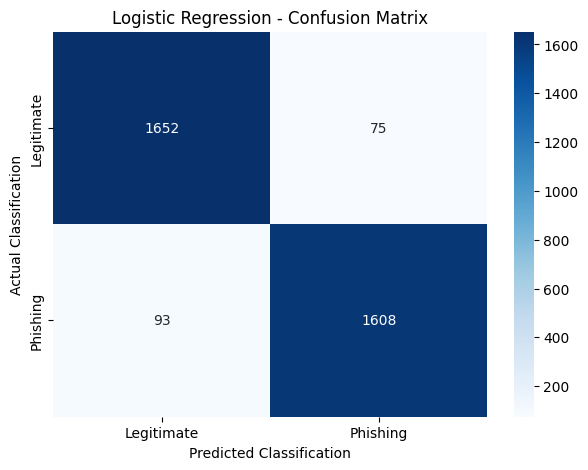

In [53]:
# Generate confusion matrix

cm_log = confusion_matrix(
    y_test,
    y_pred_log,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Logistic Regression - Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Actual Classification")

plt.show()

In [54]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_log,
        target_names=["Legitimate", "Phishing"]
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.95      0.96      0.95      1727
    Phishing       0.96      0.95      0.95      1701

    accuracy                           0.95      3428
   macro avg       0.95      0.95      0.95      3428
weighted avg       0.95      0.95      0.95      3428



### Logistic Regression – Results and Interpretation

The Logistic Regression model achieved an accuracy of 95.10%
on the testing dataset.

The precision was 95.54%, recall was 94.53%, and the F1 Score
was 95.04%.

The confusion matrix showed that 1,608 phishing websites
and 1,652 legitimate websites were correctly classified.

However, 93 phishing websites were incorrectly classified
as legitimate, while 75 legitimate websites were incorrectly
classified as phishing.

Overall, Logistic Regression demonstrated strong baseline
classification performance on the phishing website dataset.

### 6.2 Decision Tree Classifier

In [55]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [56]:
# Create Decision Tree pipeline

dt_model = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))

])

# Train the Decision Tree model

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [57]:
# Predict testing dataset

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Predictions Generated!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred_dt[:10])

Decision Tree Predictions Generated!

First 10 Actual Labels:
[0 1 1 0 1 0 1 0 1 0]

First 10 Predicted Labels:
[0 1 1 0 1 0 1 0 1 0]


In [58]:
# Calculate Decision Tree evaluation metrics

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, pos_label=1
)

dt_recall = recall_score(
    y_test, y_pred_dt, pos_label=1
)

dt_f1 = f1_score(
    y_test, y_pred_dt, pos_label=1
)

print("DECISION TREE PERFORMANCE")

print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))

DECISION TREE PERFORMANCE
Accuracy : 0.9349
Precision: 0.9352
Recall   : 0.9336
F1 Score : 0.9344


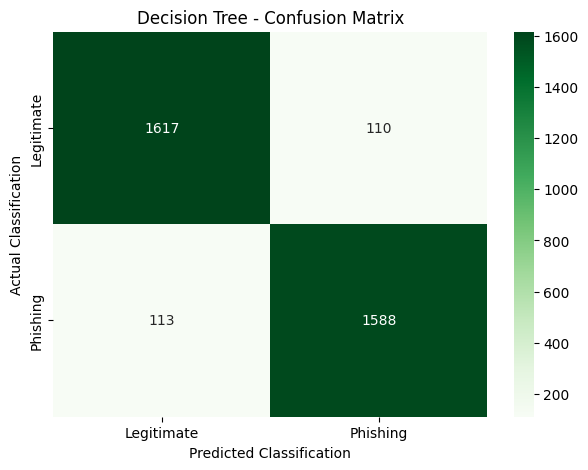

In [59]:
# Decision Tree Confusion Matrix

cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Decision Tree - Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Actual Classification")

plt.show()

In [60]:
print("DECISION TREE CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["Legitimate", "Phishing"]
    )
)

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.93      0.94      0.94      1727
    Phishing       0.94      0.93      0.93      1701

    accuracy                           0.93      3428
   macro avg       0.93      0.93      0.93      3428
weighted avg       0.93      0.93      0.93      3428



### Decision Tree – Results and Interpretation

The Decision Tree Classifier achieved an accuracy of 93.49%
on the testing dataset.

The model obtained a precision of 93.52%, recall of 93.36%,
and F1 Score of 93.44%.

The confusion matrix showed that 1,617 legitimate websites
and 1,588 phishing websites were correctly classified.

The model incorrectly classified 110 legitimate websites
as phishing and 113 phishing websites as legitimate.

When compared with Logistic Regression, the Decision Tree
showed slightly lower performance across all evaluation metrics.

Further hyperparameter optimization will be performed during
the advanced modelling stage.

### 6.3 K-Nearest Neighbours (KNN)

In [61]:
from sklearn.neighbors import KNeighborsClassifier

In [62]:
# Create KNN classification pipeline

knn_model = Pipeline([

    # Handle missing values

    ("imputer", SimpleImputer(strategy="median")),

    # Scale numerical features

    ("scaler", StandardScaler()),

    # KNN classifier

    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ))

])

# Train the model

knn_model.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [63]:
# Predict the testing dataset

y_pred_knn = knn_model.predict(X_test)

print("KNN Predictions Generated Successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred_knn[:10])

KNN Predictions Generated Successfully!

First 10 Actual Labels:
[0 1 1 0 1 0 1 0 1 0]

First 10 Predicted Labels:
[0 1 1 0 1 0 1 0 1 0]


In [64]:
# Calculate evaluation metrics

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, pos_label=1
)

knn_recall = recall_score(
    y_test, y_pred_knn, pos_label=1
)

knn_f1 = f1_score(
    y_test, y_pred_knn, pos_label=1
)

print("KNN PERFORMANCE")

print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))

KNN PERFORMANCE
Accuracy : 0.9373
Precision: 0.9476
Recall   : 0.9248
F1 Score : 0.936


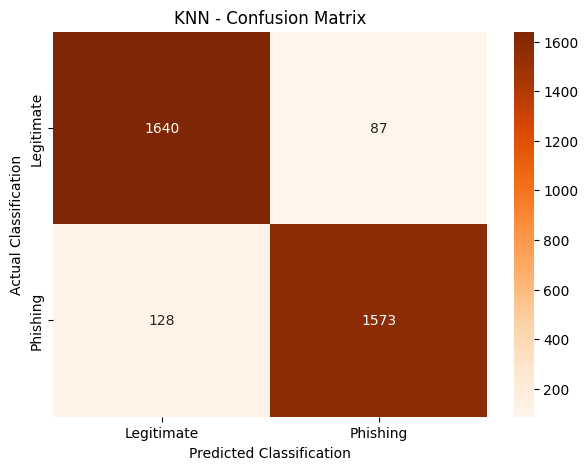

In [65]:
# Generate KNN confusion matrix

cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("KNN - Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Actual Classification")

plt.show()

In [66]:
print("KNN CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=["Legitimate", "Phishing"]
    )
)

KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.93      0.95      0.94      1727
    Phishing       0.95      0.92      0.94      1701

    accuracy                           0.94      3428
   macro avg       0.94      0.94      0.94      3428
weighted avg       0.94      0.94      0.94      3428



### K-Nearest Neighbours – Results and Interpretation

The K-Nearest Neighbours classifier achieved an accuracy
of 93.73% on the testing dataset.

The model obtained a precision of 94.76%, recall of 92.48%,
and F1 Score of 93.60%.

The confusion matrix showed that 1,640 legitimate websites
and 1,573 phishing websites were correctly classified.

The model incorrectly identified 87 legitimate websites
as phishing and 128 phishing websites as legitimate.

The KNN algorithm demonstrated good classification performance,
although its recall was comparatively lower than Logistic Regression
and Decision Tree.

## 7. Baseline Model Comparison

In [67]:
# Create baseline model comparison

baseline_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],

    "Accuracy": [
        log_accuracy,
        dt_accuracy,
        knn_accuracy
    ],

    "Precision": [
        log_precision,
        dt_precision,
        knn_precision
    ],

    "Recall": [
        log_recall,
        dt_recall,
        knn_recall
    ],

    "F1 Score": [
        log_f1,
        dt_f1,
        knn_f1
    ]
})

# Display comparison table

print("BASELINE MODEL PERFORMANCE COMPARISON")

display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

BASELINE MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9510,0.9554,0.9453,0.9504
1,Decision Tree,0.9349,0.9352,0.9336,0.9344
2,KNN,0.9373,0.9476,0.9248,0.9360


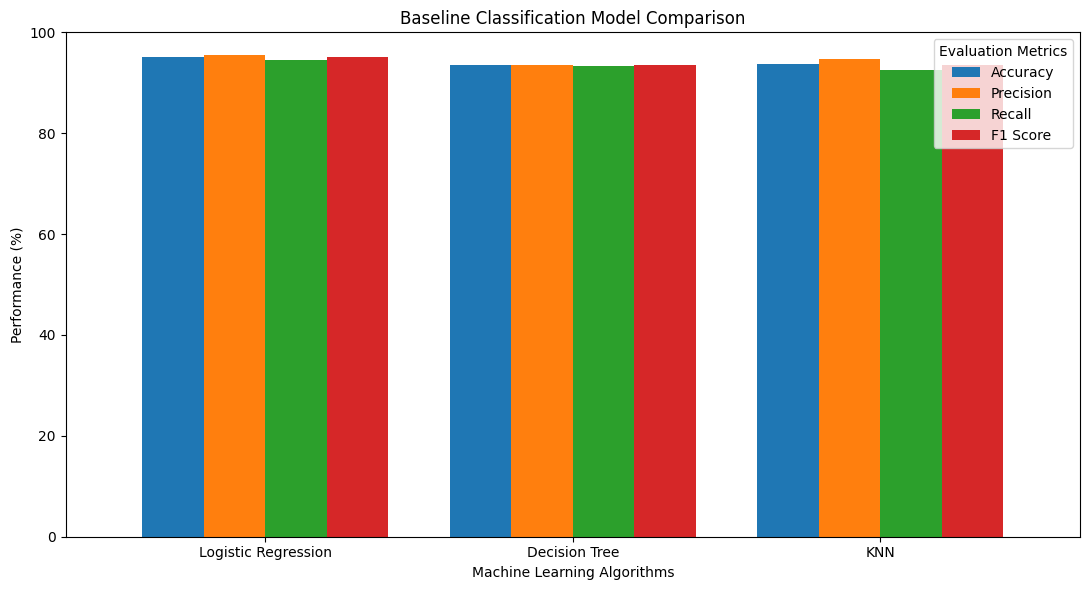

In [68]:
# Plot model performance comparison

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

baseline_plot = baseline_results.set_index("Model")[metrics] * 100

baseline_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Baseline Classification Model Comparison")

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("Performance (%)")

plt.ylim(0, 100)

plt.xticks(rotation=0)

plt.legend(title="Evaluation Metrics")

plt.tight_layout()

plt.show()

### Baseline Model Comparison – Discussion

Three supervised classification algorithms were implemented:
Logistic Regression, Decision Tree, and K-Nearest Neighbours.

Logistic Regression achieved the highest accuracy of 95.10%,
precision of 95.54%, recall of 94.53%, and F1 Score of 95.04%.

Decision Tree achieved an accuracy of 93.49%, while KNN
achieved 93.73%.

Based on the initial baseline results, Logistic Regression
demonstrated the strongest overall classification performance.

However, advanced ensemble algorithms will be implemented
to investigate whether classification performance can be improved.

### Overall Baseline Model Comparison

Three supervised classification algorithms were implemented
and evaluated: Logistic Regression, Decision Tree, and KNN.

Logistic Regression achieved the highest accuracy of 95.10%,
precision of 95.54%, recall of 94.53%, and F1 Score of 95.04%.

KNN achieved an accuracy of 93.73%, while Decision Tree
achieved 93.49%.

Based on the experimental results, Logistic Regression
demonstrated the strongest overall baseline performance.

Advanced ensemble learning algorithms will be implemented
in the next phase to investigate potential improvements.

## 8. Advanced Classification Models

### 8.1 Random Forest Classifier

In [70]:
from sklearn.ensemble import RandomForestClassifier

In [77]:
# Create Random Forest pipeline

rf_model = Pipeline([

    # Handle unavailable domain age values
    ("imputer", SimpleImputer(strategy="median")),

    # Random Forest classifier
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))

])

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [72]:
# Predict testing data

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions Generated!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred_rf[:10])

Random Forest Predictions Generated!

First 10 Actual Labels:
[0 1 1 0 1 0 1 0 1 0]

First 10 Predicted Labels:
[0 1 1 0 1 0 1 0 1 0]


In [73]:
# Calculate evaluation metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, pos_label=1
)

rf_recall = recall_score(
    y_test, y_pred_rf, pos_label=1
)

rf_f1 = f1_score(
    y_test, y_pred_rf, pos_label=1
)

print("RANDOM FOREST PERFORMANCE")

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))

RANDOM FOREST PERFORMANCE
Accuracy : 0.9717
Precision: 0.969
Recall   : 0.9741
F1 Score : 0.9716


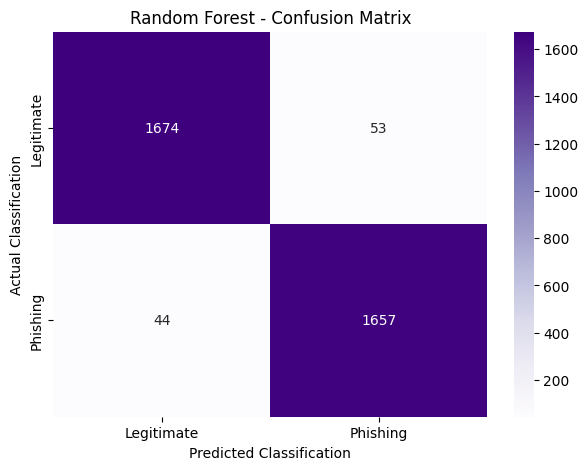

In [74]:
# Random Forest Confusion Matrix

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Random Forest - Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Actual Classification")

plt.show()

In [75]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Legitimate", "Phishing"]
    )
)

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.97      0.97      0.97      1727
    Phishing       0.97      0.97      0.97      1701

    accuracy                           0.97      3428
   macro avg       0.97      0.97      0.97      3428
weighted avg       0.97      0.97      0.97      3428



### Random Forest – Results and Interpretation

The Random Forest Classifier achieved an accuracy of 97.17%
on the testing dataset.

The model obtained a precision of 96.90%, recall of 97.41%,
and F1 Score of 97.16%.

The confusion matrix showed that 1,674 legitimate websites
and 1,657 phishing websites were correctly classified.

The model incorrectly classified 53 legitimate websites
as phishing and 44 phishing websites as legitimate.

Compared with the three baseline algorithms, Random Forest
demonstrated better performance across all four evaluation
metrics.

The results indicate that the ensemble learning approach
provides improved classification performance for the
phishing website dataset.

### 8.2 Gradient Boosting Classifier

In [79]:

from sklearn.ensemble import GradientBoostingClassifier

In [80]:
# Create Gradient Boosting pipeline

gb_model = Pipeline([

    # Handle missing domain age values
    ("imputer", SimpleImputer(strategy="median")),

    # Gradient Boosting classifier
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))

])

# Train the model

gb_model.fit(X_train, y_train)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


In [81]:
# Generate predictions

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Predictions Generated!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred_gb[:10])

Gradient Boosting Predictions Generated!

First 10 Actual Labels:
[0 1 1 0 1 0 1 0 1 0]

First 10 Predicted Labels:
[0 1 1 0 1 0 1 0 1 0]


In [82]:
# Calculate evaluation metrics

gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test, y_pred_gb, pos_label=1
)

gb_recall = recall_score(
    y_test, y_pred_gb, pos_label=1
)

gb_f1 = f1_score(
    y_test, y_pred_gb, pos_label=1
)

print("GRADIENT BOOSTING PERFORMANCE")

print("Accuracy :", round(gb_accuracy, 4))
print("Precision:", round(gb_precision, 4))
print("Recall   :", round(gb_recall, 4))
print("F1 Score :", round(gb_f1, 4))

GRADIENT BOOSTING PERFORMANCE
Accuracy : 0.9641
Precision: 0.9641
Recall   : 0.9636
F1 Score : 0.9638


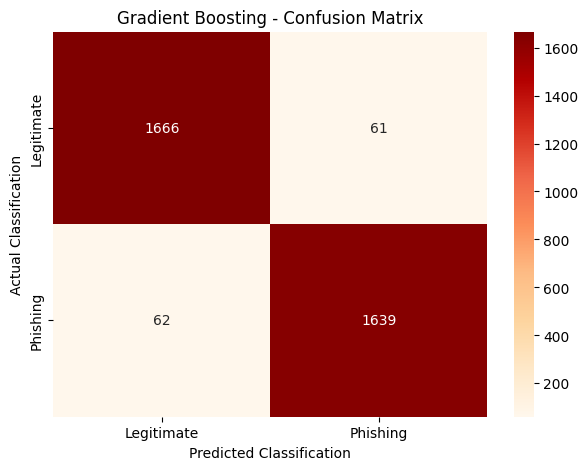

In [83]:
# Gradient Boosting Confusion Matrix

cm_gb = confusion_matrix(
    y_test,
    y_pred_gb,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="OrRd",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Gradient Boosting - Confusion Matrix")

plt.xlabel("Predicted Classification")

plt.ylabel("Actual Classification")

plt.show()

In [84]:
print("GRADIENT BOOSTING CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=["Legitimate", "Phishing"]
    )
)

GRADIENT BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1727
    Phishing       0.96      0.96      0.96      1701

    accuracy                           0.96      3428
   macro avg       0.96      0.96      0.96      3428
weighted avg       0.96      0.96      0.96      3428



### Gradient Boosting – Results and Interpretation

The Gradient Boosting Classifier achieved an accuracy of
96.41% on the testing dataset.

The model obtained a precision of 96.41%, recall of 96.36%,
and F1 Score of 96.38%.

The confusion matrix showed that 1,666 legitimate websites
and 1,639 phishing websites were correctly classified.

The model incorrectly classified 61 legitimate websites
as phishing and 62 phishing websites as legitimate.

Gradient Boosting demonstrated strong classification
performance, although Random Forest performed better
across all four evaluation metrics in this experiment.

In [85]:
# Combine all five classification models

all_model_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Accuracy": [
        log_accuracy,
        dt_accuracy,
        knn_accuracy,
        rf_accuracy,
        gb_accuracy
    ],

    "Precision": [
        log_precision,
        dt_precision,
        knn_precision,
        rf_precision,
        gb_precision
    ],

    "Recall": [
        log_recall,
        dt_recall,
        knn_recall,
        rf_recall,
        gb_recall
    ],

    "F1 Score": [
        log_f1,
        dt_f1,
        knn_f1,
        rf_f1,
        gb_f1
    ]
})

print("OVERALL CLASSIFICATION MODEL COMPARISON")

display(
    all_model_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

OVERALL CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9510,0.9554,0.9453,0.9504
1,Decision Tree,0.9349,0.9352,0.9336,0.9344
2,KNN,0.9373,0.9476,0.9248,0.9360
3,Random Forest,0.9717,0.9690,0.9741,0.9716
4,Gradient Boosting,0.9641,0.9641,0.9636,0.9638


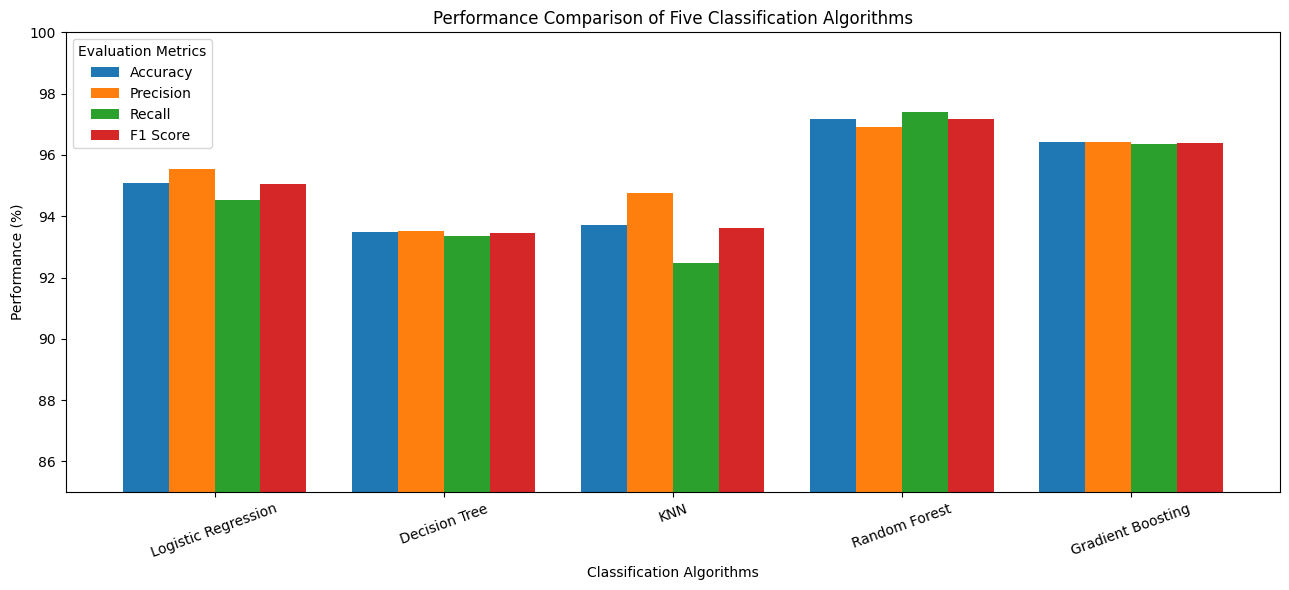

In [86]:
# Visual comparison of all five algorithms

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

plot_data = (
    all_model_results
    .set_index("Model")[metrics] * 100
)

plot_data.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Algorithms")

plt.xlabel("Classification Algorithms")
plt.ylabel("Performance (%)")
plt.ylim(85, 100)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

### Overall Classification Model Comparison – Discussion

Five supervised machine learning algorithms were implemented
and evaluated.

Random Forest achieved the highest accuracy of 97.17%,
precision of 96.90%, recall of 97.41%, and F1 Score of 97.16%.

Gradient Boosting achieved an accuracy of 96.41%, while
Logistic Regression achieved 95.10%.

The ensemble-based Random Forest classifier demonstrated
the strongest overall performance among the five initial models.

Random Forest also produced fewer false negatives than
the other models, correctly identifying 1,657 phishing
websites in the test dataset.

Therefore, Random Forest is currently the leading candidate
for the final classification model.

Hyperparameter optimization will be conducted to investigate
whether its performance can be further improved.

In [87]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

In [88]:
# Create Random Forest pipeline for optimization

rf_tune_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))

])

In [89]:
# Define parameter grid

rf_param_grid = {

    "classifier__n_estimators": [100, 200],

    "classifier__max_depth": [None, 20],

    "classifier__min_samples_leaf": [1, 2]

}

print("Random Forest Parameter Grid:")
print(rf_param_grid)

Random Forest Parameter Grid:
{'classifier__n_estimators': [100, 200], 'classifier__max_depth': [None, 20], 'classifier__min_samples_leaf': [1, 2]}


In [90]:
# Create 5-fold stratified group cross-validation

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configure GridSearchCV

rf_grid_search = GridSearchCV(

    estimator=rf_tune_pipeline,

    param_grid=rf_param_grid,

    scoring="f1",

    cv=group_cv,

    n_jobs=-1,

    verbose=1,

    return_train_score=True

)

print("GridSearchCV configured successfully!")

GridSearchCV configured successfully!


In [91]:
# Retrieve URL groups corresponding to training records

train_groups = groups.iloc[train_indices]

# Perform hyperparameter tuning on training data only

rf_grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Random Forest Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Random Forest Hyperparameter Tuning Completed!


In [92]:
print("BEST RANDOM FOREST PARAMETERS")

print(rf_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1 SCORE")

print(round(rf_grid_search.best_score_, 4))

BEST RANDOM FOREST PARAMETERS
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

BEST CROSS-VALIDATION F1 SCORE
0.9656


In [93]:
# Retrieve the optimized model

best_rf_model = rf_grid_search.best_estimator_

# Predict testing data

y_pred_best_rf = best_rf_model.predict(X_test)

# Calculate final metrics

best_rf_accuracy = accuracy_score(y_test, y_pred_best_rf)

best_rf_precision = precision_score(
    y_test, y_pred_best_rf
)

best_rf_recall = recall_score(
    y_test, y_pred_best_rf
)

best_rf_f1 = f1_score(
    y_test, y_pred_best_rf
)

print("OPTIMIZED RANDOM FOREST PERFORMANCE")

print("Accuracy :", round(best_rf_accuracy, 4))
print("Precision:", round(best_rf_precision, 4))
print("Recall   :", round(best_rf_recall, 4))
print("F1 Score :", round(best_rf_f1, 4))

OPTIMIZED RANDOM FOREST PERFORMANCE
Accuracy : 0.9679
Precision: 0.9649
Recall   : 0.9706
F1 Score : 0.9678


Starting Gradient Boosting Hyperparameter Tuning...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Gradient Boosting Hyperparameter Tuning Completed!

BEST GRADIENT BOOSTING PARAMETERS
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 150}

BEST CROSS-VALIDATION F1 SCORE
0.9595

OPTIMIZED GRADIENT BOOSTING PERFORMANCE
Accuracy : 0.9647
Precision: 0.9642
Recall   : 0.9647
F1 Score : 0.9644


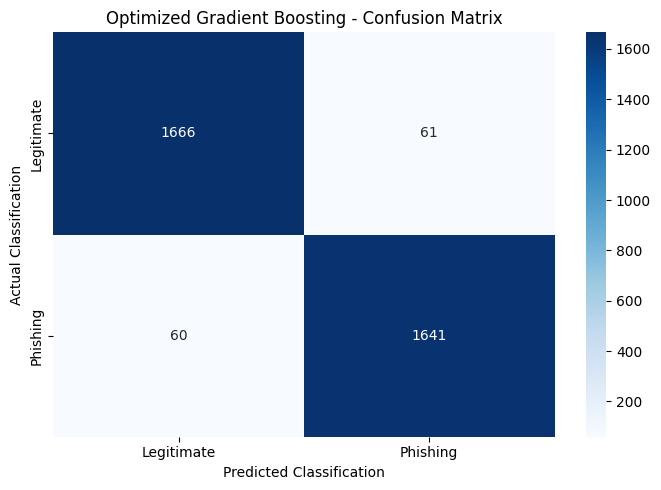


OPTIMIZED GRADIENT BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.97      0.96      0.96      1727
    Phishing       0.96      0.96      0.96      1701

    accuracy                           0.96      3428
   macro avg       0.96      0.96      0.96      3428
weighted avg       0.96      0.96      0.96      3428



In [94]:
# ============================================================
# GRADIENT BOOSTING - HYPERPARAMETER OPTIMIZATION
# Using GridSearchCV and Stratified Group Cross-Validation
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# STEP 1: Create Gradient Boosting Pipeline

gb_tune_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GradientBoostingClassifier(random_state=42))
])


# STEP 2: Define Hyperparameter Grid

gb_param_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3]
}


# STEP 3: Configure Cross-Validation

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_groups = groups.iloc[train_indices]


# STEP 4: Configure GridSearchCV

gb_grid_search = GridSearchCV(
    estimator=gb_tune_pipeline,
    param_grid=gb_param_grid,
    scoring="f1",
    cv=group_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)


# STEP 5: Perform Hyperparameter Tuning

print("Starting Gradient Boosting Hyperparameter Tuning...")

gb_grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("\nGradient Boosting Hyperparameter Tuning Completed!")


# STEP 6: Display Best Parameters

print("\nBEST GRADIENT BOOSTING PARAMETERS")

print(gb_grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1 SCORE")

print(round(gb_grid_search.best_score_, 4))


# STEP 7: Retrieve Optimized Model

best_gb_model = gb_grid_search.best_estimator_


# STEP 8: Generate Predictions

y_pred_best_gb = best_gb_model.predict(X_test)


# STEP 9: Calculate Evaluation Metrics

best_gb_accuracy = accuracy_score(y_test, y_pred_best_gb)

best_gb_precision = precision_score(y_test, y_pred_best_gb)

best_gb_recall = recall_score(y_test, y_pred_best_gb)

best_gb_f1 = f1_score(y_test, y_pred_best_gb)


print("\nOPTIMIZED GRADIENT BOOSTING PERFORMANCE")

print("Accuracy :", round(best_gb_accuracy, 4))
print("Precision:", round(best_gb_precision, 4))
print("Recall   :", round(best_gb_recall, 4))
print("F1 Score :", round(best_gb_f1, 4))


# STEP 10: Generate Confusion Matrix

cm_best_gb = confusion_matrix(
    y_test,
    y_pred_best_gb,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_best_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Optimized Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Classification")
plt.ylabel("Actual Classification")

plt.tight_layout()
plt.show()


# STEP 11: Classification Report

print("\nOPTIMIZED GRADIENT BOOSTING CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_best_gb,
        target_names=["Legitimate", "Phishing"]
    )
)

# ============================================================
# END OF GRADIENT BOOSTING OPTIMIZATION
# ============================================================

### Gradient Boosting – Hyperparameter Optimization

GridSearchCV was used to optimize the Gradient Boosting
Classifier through five-fold Stratified Group
Cross-Validation.

The best parameters were:

- n_estimators = 150
- learning_rate = 0.1
- max_depth = 3

The best cross-validation F1 Score was 95.95%.

The optimized model achieved 96.47% accuracy,
96.42% precision, 96.47% recall, and 96.44% F1 Score.

Compared with the initial Gradient Boosting model,
the optimized model showed a slight improvement in
overall test performance.

## 12. Cross-Validation Analysis

In [95]:
# ============================================================
# CROSS-VALIDATION ANALYSIS - FIVE CLASSIFICATION MODELS
# ============================================================

from sklearn.model_selection import cross_validate

# Define all five baseline models

models = {
    "Logistic Regression": log_reg_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

# Define evaluation metrics

scoring_metrics = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1 Score": "f1"
}

cv_results_list = []

print("STARTING FIVE-FOLD CROSS-VALIDATION")

# Evaluate each model

for name, model in models.items():

    print(f"\nEvaluating: {name}")

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        groups=train_groups,
        cv=group_cv,
        scoring=scoring_metrics,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    # Store mean and standard deviation

    result = {"Model": name}

    for metric in scoring_metrics:

        values = scores["test_" + metric]

        result[metric + " Mean"] = values.mean()

        result[metric + " Std"] = values.std()

    cv_results_list.append(result)

    print("Cross-validation completed!")


# Create final comparison table

cv_comparison = pd.DataFrame(cv_results_list)

print("\nCROSS-VALIDATION PERFORMANCE COMPARISON")

display(
    cv_comparison.style.format({
        col: "{:.4f}"
        for col in cv_comparison.columns
        if col != "Model"
    })
)

# ============================================================
# END OF CROSS-VALIDATION ANALYSIS
# ============================================================

STARTING FIVE-FOLD CROSS-VALIDATION

Evaluating: Logistic Regression
Cross-validation completed!

Evaluating: Decision Tree
Cross-validation completed!

Evaluating: KNN
Cross-validation completed!

Evaluating: Random Forest
Cross-validation completed!

Evaluating: Gradient Boosting
Cross-validation completed!

CROSS-VALIDATION PERFORMANCE COMPARISON


,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Score Mean,F1 Score Std
0,Logistic Regression,0.9459,0.0037,0.9479,0.0063,0.9442,0.0072,0.9460,0.0030
1,Decision Tree,0.9329,0.0077,0.9309,0.0106,0.9358,0.0092,0.9333,0.0075
2,KNN,0.9366,0.0050,0.9545,0.0058,0.9175,0.0080,0.9356,0.0050
3,Random Forest,0.9651,0.0034,0.9666,0.0048,0.9639,0.0037,0.9652,0.0031
4,Gradient Boosting,0.9576,0.0042,0.9602,0.0050,0.9552,0.0058,0.9577,0.0039


### Cross-Validation Analysis – Results and Discussion

Five-fold Stratified Group Cross-Validation was performed
to evaluate the consistency of the five classification models.

Random Forest achieved the highest mean accuracy of 96.51%
and mean F1 Score of 96.52%, demonstrating the strongest
average performance.

Gradient Boosting achieved the second-highest mean F1 Score
of 95.77%.

Logistic Regression achieved a mean F1 Score of 94.60%,
while KNN and Decision Tree achieved 93.56% and 93.33%,
respectively.

The Random Forest model also showed relatively low variation
across the validation folds, indicating consistent performance.

Based on cross-validation, Random Forest is the leading
classification algorithm in this experiment.

## 13. ROC Curve and AUC Score Analysis

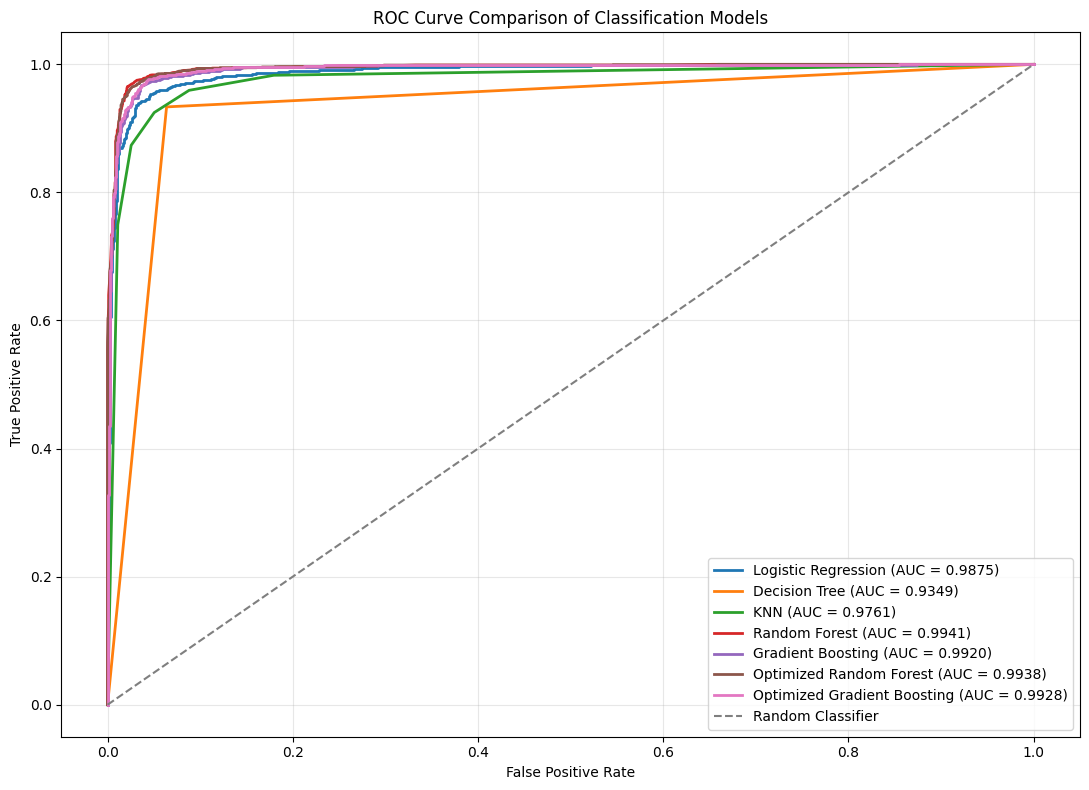

ROC-AUC MODEL COMPARISON


,Model,AUC Score
0,Random Forest,0.9941
1,Optimized Random Forest,0.9938
2,Optimized Gradient Boosting,0.9928
3,Gradient Boosting,0.9920
4,Logistic Regression,0.9875
5,KNN,0.9761
6,Decision Tree,0.9349


In [96]:
# ============================================================
# ROC CURVE AND AUC SCORE ANALYSIS
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score

# STEP 1: Define all models

roc_models = {

    "Logistic Regression": log_reg_model,

    "Decision Tree": dt_model,

    "KNN": knn_model,

    "Random Forest": rf_model,

    "Gradient Boosting": gb_model,

    "Optimized Random Forest": best_rf_model,

    "Optimized Gradient Boosting": best_gb_model

}


# STEP 2: Initialize results

roc_results = []

plt.figure(figsize=(11, 8))


# STEP 3: Calculate ROC and AUC for each model

for name, model in roc_models.items():

    # Get phishing probability

    y_probability = model.predict_proba(X_test)[:, 1]

    # Calculate ROC values

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability,
        pos_label=1
    )

    # Calculate AUC

    auc_score = roc_auc_score(
        y_test,
        y_probability
    )

    # Store results

    roc_results.append({

        "Model": name,

        "AUC Score": auc_score

    })

    # Plot ROC Curve

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )


# STEP 4: Plot random classifier reference

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


# STEP 5: Customize graph

plt.title("ROC Curve Comparison of Classification Models")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# STEP 6: Display AUC comparison table

roc_auc_df = pd.DataFrame(roc_results)

roc_auc_df = roc_auc_df.sort_values(
    by="AUC Score",
    ascending=False
).reset_index(drop=True)

print("ROC-AUC MODEL COMPARISON")

display(
    roc_auc_df.style.format({
        "AUC Score": "{:.4f}"
    })
)

# ============================================================
# END OF ROC-AUC ANALYSIS
# ============================================================

### ROC Curve and AUC Analysis – Results and Discussion

ROC Curve analysis was performed to evaluate the ability
of the classification models to distinguish between
phishing and legitimate websites.

Random Forest achieved the highest AUC Score of 0.9941,
followed by Optimized Random Forest with 0.9938.

Optimized Gradient Boosting achieved 0.9928, while the
initial Gradient Boosting model achieved 0.9920.

Logistic Regression and KNN achieved AUC scores of
0.9875 and 0.9761, respectively.

Decision Tree achieved the lowest AUC score of 0.9349.

The results indicate that Random Forest demonstrated
the strongest class discrimination performance among
the evaluated models.

## 14. Feature Importance Analysis

### 14.1 Random Forest Feature Importance

TOP 15 RANDOM FOREST FEATURES


,Feature,Importance
0,google_index,0.164357
1,page_rank,0.114896
2,web_traffic,0.072643
3,nb_hyperlinks,0.068063
4,domain_age,0.045394
5,nb_www,0.042022
6,ratio_extHyperlinks,0.036780
7,longest_word_path,0.028978
8,ratio_intHyperlinks,0.025570
9,phish_hints,0.025125


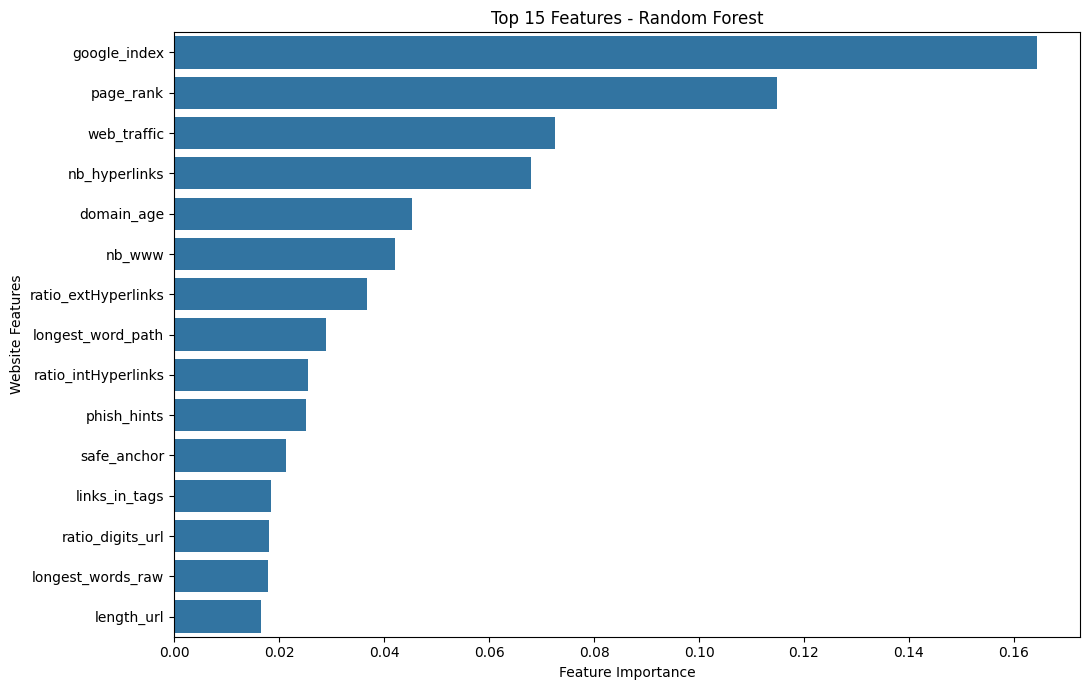


TOP 15 GRADIENT BOOSTING FEATURES


,Feature,Importance
0,google_index,0.580998
1,page_rank,0.120146
2,nb_hyperlinks,0.084886
3,domain_age,0.040885
4,nb_www,0.032251
5,web_traffic,0.027951
6,nb_qm,0.017514
7,phish_hints,0.010843
8,longest_word_path,0.008606
9,length_url,0.007560


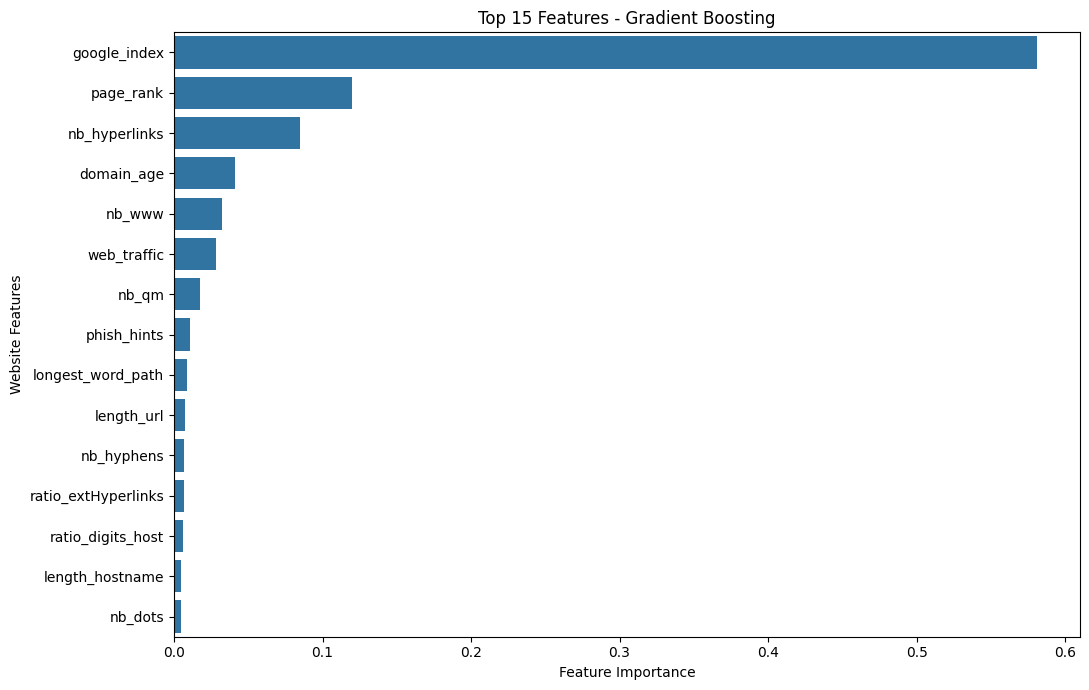

In [97]:
# ============================================================
# FEATURE IMPORTANCE ANALYSIS
# RANDOM FOREST AND GRADIENT BOOSTING
# ============================================================

# STEP 1: Extract Random Forest feature importance

rf_classifier = rf_model.named_steps["classifier"]

rf_importance = rf_classifier.feature_importances_

rf_importance_df = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": rf_importance

})

# Sort in descending order

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# STEP 2: Display Top 15 Random Forest Features

print("TOP 15 RANDOM FOREST FEATURES")

display(rf_importance_df.head(15))


# STEP 3: Visualize Random Forest Feature Importance

plt.figure(figsize=(11, 7))

sns.barplot(
    data=rf_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")

plt.xlabel("Feature Importance")

plt.ylabel("Website Features")

plt.tight_layout()

plt.show()


# STEP 4: Extract Gradient Boosting Feature Importance

gb_classifier = gb_model.named_steps["classifier"]

gb_importance = gb_classifier.feature_importances_

gb_importance_df = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": gb_importance

})

# Sort in descending order

gb_importance_df = gb_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# STEP 5: Display Top 15 Gradient Boosting Features

print("\nTOP 15 GRADIENT BOOSTING FEATURES")

display(gb_importance_df.head(15))


# STEP 6: Visualize Gradient Boosting Feature Importance

plt.figure(figsize=(11, 7))

sns.barplot(
    data=gb_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Gradient Boosting")

plt.xlabel("Feature Importance")

plt.ylabel("Website Features")

plt.tight_layout()

plt.show()


# ============================================================
# END OF FEATURE IMPORTANCE ANALYSIS
# ============================================================

### Feature Importance Analysis – Results and Discussion

Feature importance analysis was performed using Random Forest
and Gradient Boosting classifiers to identify the most
influential website characteristics.

In Random Forest, google_index was the most important feature
with an importance score of 0.164357, followed by page_rank
with 0.114896 and web_traffic with 0.072643.

Other important features included nb_hyperlinks, domain_age,
nb_www, and ratio_extHyperlinks.

In Gradient Boosting, google_index had the highest importance
score of 0.580998, followed by page_rank with 0.120146 and
nb_hyperlinks with 0.084886.

Both algorithms identified google_index, page_rank,
nb_hyperlinks, domain_age, and nb_www among their important
predictive features.

However, the relative importance of features differed
between the two algorithms.

The findings demonstrate that URL characteristics,
website structure, domain-related information, and
external website indicators contribute to phishing
website classification.

FINAL CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV F1
0,Random Forest,0.9717,0.9690,0.9741,0.9716,0.9941,0.9652
1,Optimized Random Forest,0.9679,0.9649,0.9706,0.9678,0.9938,0.9656
2,Optimized Gradient Boosting,0.9647,0.9642,0.9647,0.9644,0.9928,0.9595
3,Gradient Boosting,0.9641,0.9641,0.9636,0.9638,0.9920,0.9577
4,Logistic Regression,0.9510,0.9554,0.9453,0.9504,0.9875,0.9460
5,KNN,0.9373,0.9476,0.9248,0.9360,0.9761,0.9356
6,Decision Tree,0.9349,0.9352,0.9336,0.9344,0.9349,0.9333



BEST MODEL BASED ON TEST ACCURACY:
Random Forest


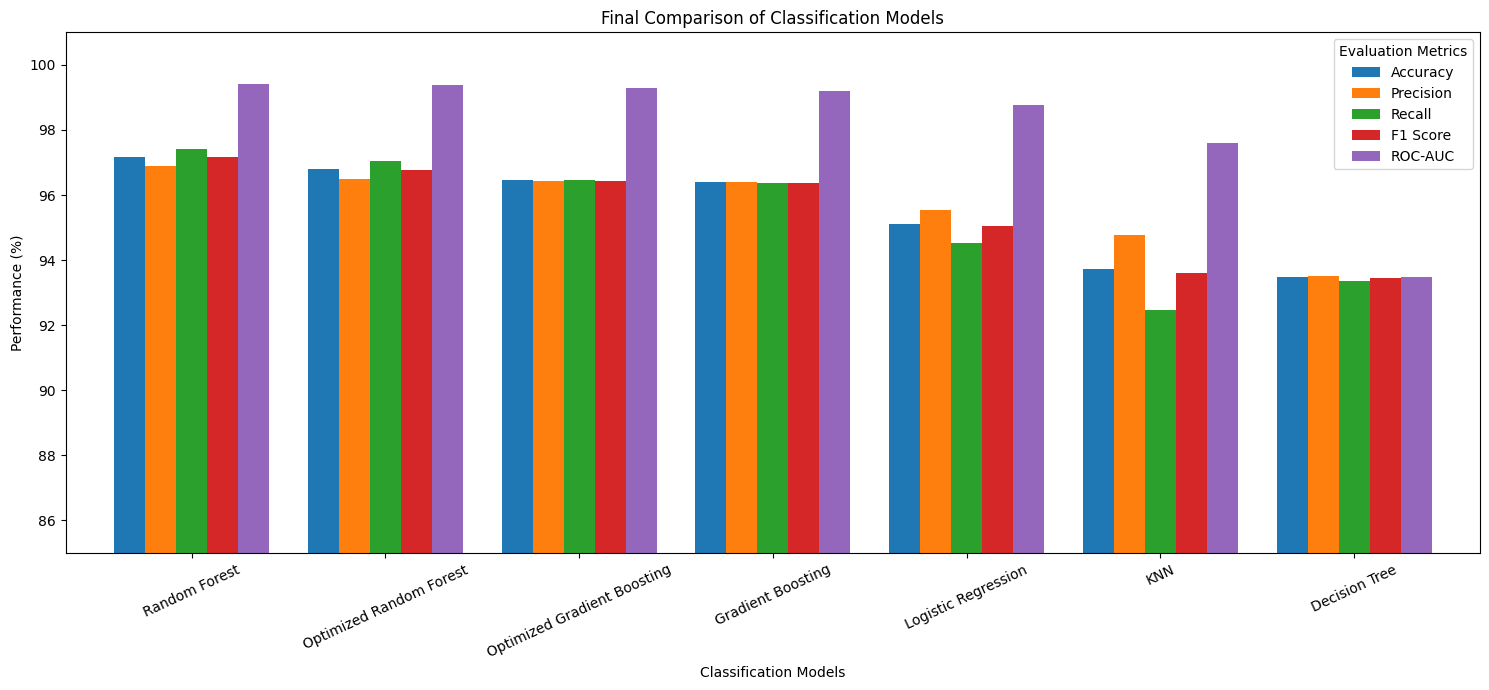

In [98]:
# ============================================================
# FINAL CLASSIFICATION MODEL COMPARISON
# ============================================================

# Retrieve AUC scores

auc_scores = roc_auc_df.set_index("Model")["AUC Score"].to_dict()

# Retrieve baseline cross-validation F1 scores

cv_f1_scores = cv_comparison.set_index("Model")[
    "F1 Score Mean"
].to_dict()


# Define final model results

final_results = [

    {
        "Model": "Logistic Regression",
        "Accuracy": log_accuracy,
        "Precision": log_precision,
        "Recall": log_recall,
        "F1 Score": log_f1,
        "ROC-AUC": auc_scores["Logistic Regression"],
        "CV F1": cv_f1_scores["Logistic Regression"]
    },

    {
        "Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1,
        "ROC-AUC": auc_scores["Decision Tree"],
        "CV F1": cv_f1_scores["Decision Tree"]
    },

    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1,
        "ROC-AUC": auc_scores["KNN"],
        "CV F1": cv_f1_scores["KNN"]
    },

    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1,
        "ROC-AUC": auc_scores["Random Forest"],
        "CV F1": cv_f1_scores["Random Forest"]
    },

    {
        "Model": "Gradient Boosting",
        "Accuracy": gb_accuracy,
        "Precision": gb_precision,
        "Recall": gb_recall,
        "F1 Score": gb_f1,
        "ROC-AUC": auc_scores["Gradient Boosting"],
        "CV F1": cv_f1_scores["Gradient Boosting"]
    },

    {
        "Model": "Optimized Random Forest",
        "Accuracy": best_rf_accuracy,
        "Precision": best_rf_precision,
        "Recall": best_rf_recall,
        "F1 Score": best_rf_f1,
        "ROC-AUC": auc_scores["Optimized Random Forest"],
        "CV F1": rf_grid_search.best_score_
    },

    {
        "Model": "Optimized Gradient Boosting",
        "Accuracy": best_gb_accuracy,
        "Precision": best_gb_precision,
        "Recall": best_gb_recall,
        "F1 Score": best_gb_f1,
        "ROC-AUC": auc_scores["Optimized Gradient Boosting"],
        "CV F1": gb_grid_search.best_score_
    }

]


# Create comparison DataFrame

final_comparison = pd.DataFrame(final_results)

# Sort by test accuracy

final_comparison = final_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)


# Display final results

print("FINAL CLASSIFICATION MODEL COMPARISON")

display(
    final_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "CV F1": "{:.4f}"
    })
)


# Identify highest test accuracy model

best_model_name = final_comparison.iloc[0]["Model"]

print("\nBEST MODEL BASED ON TEST ACCURACY:")
print(best_model_name)


# Plot final model comparison

final_plot = final_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
] * 100

final_plot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Final Comparison of Classification Models")

plt.xlabel("Classification Models")
plt.ylabel("Performance (%)")
plt.ylim(85, 101)
plt.xticks(rotation=25)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

# ============================================================
# END OF FINAL MODEL COMPARISON
# ============================================================

## 15. Final Model Selection and Justification

After evaluating all five classification algorithms and their
optimized configurations, Random Forest was selected as the
final model.

The model achieved 97.17% accuracy, 96.90% precision,
97.41% recall, and 97.16% F1 Score on the testing dataset.

It also achieved the highest ROC-AUC score of 0.9941.

The five-fold cross-validation analysis produced a mean
F1 Score of 96.52%, demonstrating consistent performance
across validation folds.

Although hyperparameter optimization was performed,
the initial Random Forest model achieved better performance
on the held-out testing dataset than the optimized version.

Therefore, the original Random Forest classifier was selected
as the final model based on its overall experimental results.

In [99]:
# ============================================================
# FINAL SELECTED MODEL
# ============================================================

# Select original Random Forest as final model

final_model = rf_model

# Generate final predictions

final_predictions = final_model.predict(X_test)

# Generate predicted probabilities

final_probabilities = final_model.predict_proba(X_test)[:, 1]

# Final evaluation

print("FINAL MODEL: RANDOM FOREST")

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))

# Display classification report

print("\nFINAL CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

FINAL MODEL: RANDOM FOREST
Accuracy: 0.9717
Precision: 0.969
Recall: 0.9741
F1 Score: 0.9716
ROC-AUC: 0.9941

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.97      0.97      0.97      1727
    Phishing       0.97      0.97      0.97      1701

    accuracy                           0.97      3428
   macro avg       0.97      0.97      0.97      3428
weighted avg       0.97      0.97      0.97      3428



In [100]:
import joblib

# Save the complete trained pipeline

joblib.dump(
    final_model,
    "phishing_detection_random_forest.pkl"
)

print("Final Random Forest model saved successfully!")

Final Random Forest model saved successfully!


## 16. Business Insights and Cybersecurity Applications

The developed phishing website detection model demonstrates
the application of supervised machine learning in cybersecurity.

The analysis identified several important website characteristics,
including Google indexing information, page rank, web traffic,
hyperlink counts, domain age, and phishing-related URL indicators.

These features contributed to the classification decisions
made by the ensemble learning algorithms.

The selected Random Forest classifier achieved 97.17%
accuracy on the testing dataset, demonstrating its potential
as a supporting mechanism for identifying suspicious websites.

Potential applications include:

1. Browser security systems.
2. Website risk assessment.
3. Cybersecurity monitoring platforms.
4. Online fraud prevention systems.
5. Web security gateways.

The proposed system can support security professionals
by identifying potentially malicious website characteristics.

However, it should be used alongside other security
mechanisms rather than as a complete replacement for
existing cybersecurity infrastructure.

## 17. Limitations

1. The project uses a historical dataset, and phishing
techniques may evolve over time.

2. The model uses pre-extracted website features rather
than analysing live websites.

3. Certain external-service features, such as Google indexing,
page rank, and web traffic, may not always be available
during real-time predictions.

4. False positive and false negative predictions are possible.

5. High performance on this dataset does not guarantee
similar results on newly collected websites.

6. The feature importance results indicate predictive
contribution and do not establish causation.


## 18. Future Scope

1. Integrate real-time URL feature extraction.

2. Use continuously updated phishing website datasets.

3. Develop a browser-based phishing detection extension.

4. Explore deep learning approaches.

5. Integrate explainable AI techniques.

6. Develop a real-time phishing detection dashboard.

7. Evaluate the model against previously unseen
and recently emerging phishing attacks.

## 19. Conclusion

This project successfully demonstrates the implementation
of supervised machine learning techniques for phishing
website detection.

The Web Page Phishing Detection dataset containing 11,430
records was analysed and preprocessed to identify useful
website characteristics.

Exploratory Data Analysis was performed to examine feature
distributions, correlations, outliers, and target class
distribution.

Five classification algorithms were implemented:
Logistic Regression, Decision Tree, K-Nearest Neighbours,
Random Forest, and Gradient Boosting.

Advanced techniques including GridSearchCV, cross-validation,
ROC Curve analysis, AUC evaluation, and feature importance
analysis were also performed.

Among all evaluated configurations, the initial Random
Forest classifier demonstrated the strongest overall
performance.

It achieved an accuracy of 97.17%, precision of 96.90%,
recall of 97.41%, F1 Score of 97.16%, and ROC-AUC of 0.9941.

The analysis identified Google indexing information,
page rank, web traffic, hyperlinks, and domain age among
the important predictive features.

Overall, the project demonstrates how supervised machine
learning can support cybersecurity by identifying potentially
phishing websites based on their extracted characteristics.

### Final Random Forest Model – Performance Evaluation

The Random Forest Classifier was selected as the final
model based on its comparative performance.

The model achieved an accuracy of 97.17%, precision of
96.90%, recall of 97.41%, and F1 Score of 97.16%.

The ROC-AUC score was 0.9941, indicating excellent
discriminative performance on the testing dataset.

Out of 3,428 testing records, the model correctly classified
3,331 websites.

The model correctly identified 1,657 phishing websites
and 1,674 legitimate websites.

It incorrectly classified 53 legitimate websites as
phishing and 44 phishing websites as legitimate.

These results demonstrate the effectiveness of the
Random Forest algorithm for the given phishing website
classification dataset.

In [101]:
# =====================================================
# FINAL PROJECT VERIFICATION
# =====================================================

print("PHISHING WEBSITE DETECTION PROJECT")
print("=" * 50)

# Dataset verification
print("\n1. DATASET")

print("Total Records:", len(df))
print("Original Features:", df.shape[1])

# Model input verification
print("\n2. MODEL INPUT")

print("Number of Features:", X_train.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

# Leakage verification
print("\n3. DATA LEAKAGE CHECK")

print("Overlapping URLs:",
      len(set(groups.iloc[train_indices]) &
          set(groups.iloc[test_indices])))

# Final model verification
print("\n4. FINAL MODEL")

print("Selected Model: Random Forest")

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))

# Final validation
assert len(df) == 11430
assert X_train.shape[1] == 82
assert len(final_predictions) == len(y_test)
assert len(set(groups.iloc[train_indices]) &
           set(groups.iloc[test_indices])) == 0

print("\n" + "=" * 50)
print("PROJECT VERIFICATION COMPLETED")
print("=" * 50)

PHISHING WEBSITE DETECTION PROJECT

1. DATASET
Total Records: 11430
Original Features: 89

2. MODEL INPUT
Number of Features: 82
Training Records: 8002
Testing Records: 3428

3. DATA LEAKAGE CHECK
Overlapping URLs: 0

4. FINAL MODEL
Selected Model: Random Forest
Accuracy: 0.9717
Precision: 0.969
Recall: 0.9741
F1 Score: 0.9716
ROC-AUC: 0.9941

PROJECT VERIFICATION COMPLETED
